# 📰 Arabic Fake News Detection

In this notebook we build a simple machine-learning pipeline that classifies Arabic news as **real** or **fake**.

**Steps:**
1. Setup and load the data
2. Explore the data (with simple charts)
3. Clean the Arabic text
4. Convert text to numbers (TF-IDF)
5. Train 3 models: Logistic Regression, Random Forest, SVM
6. Compare the models and test on new text

## 1. Setup


In [1]:
import re
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem.isri import ISRIStemmer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

nltk.download('stopwords')

sns.set_style('whitegrid')   # clean look for all charts

[nltk_data] Error loading stopwords: <urlopen error [WinError 10054]
[nltk_data]     An existing connection was forcibly closed by the
[nltk_data]     remote host>


## 2. Load the Data


In [4]:
df = pd.read_csv(r'D:\00jupters-notebook\00Computer-Vision\NLU-Project\Fake_News_Detection-NLP-\data\raw\merged_cleaned.csv')
df.head()

,Id,date,platform,title,News content,Label
0,1,2023-01-11 00:00:00,Aljazeera,الضفة الغربية.. الاحتلال يهدم 17 منزلا تاريخيا...,هدمت قوات الاحتلال الإسرائيلي -اليوم الأربعاء-...,real
1,2,2023-01-11 00:00:00,Aljazeera,مظاهرات بمدن أوروبية تضامنا مع غزة وحشود أمام ...,خرجت مظاهرات في عدد من المدن الأوروبية مساء ال...,real
2,3,2023-01-11 00:00:00,Aljazeera,شهداء في جنين وطولكرم وإضراب عام بالضفة الغربي...,استشهد 4 فلسطينيين واعتقل عشرات آخرون -اليوم ا...,real
3,4,2023-02-11 00:00:00,Aljazeera,أبو عبيدة: خسائر العدو أكبر بكثير مما يعلن وسن...,أكد الناطق باسمكتائب الشهيد عز الدين القسام-ال...,real
4,5,2023-03-11 00:00:00,Aljazeera,9 شهداء بالضفة والاحتلال يشن حملة اعتقالات,استشهد 9 فلسطينيين في مواجهات اندلعت مع قوات ا...,real


### 2.1Dataset Rows
Display the total number of rows in the dataset.

In [6]:
print(f"Rows: {df.shape[0]}")

Rows: 5352


### 2.2Dataset Columns
Display the total number of columns in the dataset.

In [7]:
print(f"Columns: {df.shape[1]}")

Columns: 6


### 2.3Missing Values
Check the number of missing values in each column.

In [8]:
print(df.isnull().sum())

Id              0
date            0
platform        0
title           0
News content    0
Label           0
dtype: int64


### 2.4Duplicate News Texts
Check the number of duplicated news articles in the dataset.

In [9]:
print(df['News content'].duplicated().sum())

23


## 3. Data Exploration


### 3.1 Label Distribution
Count the number of real and fake news articles in the dataset.

In [11]:
label_counts = df['Label'].value_counts()

print(label_counts)

Label
real    3913
fake    1439
Name: count, dtype: int64


### 3.2 Label Distribution (Percentages)
Calculate the percentage of real and fake news articles.

In [13]:
label_percent = df['Label'].value_counts(normalize=True) * 100

print(label_percent.round(2))

Label
real    73.11
fake    26.89
Name: proportion, dtype: float64


### 3.3 Number of Articles by Label
Visualize the number of real and fake news articles using a bar chart.

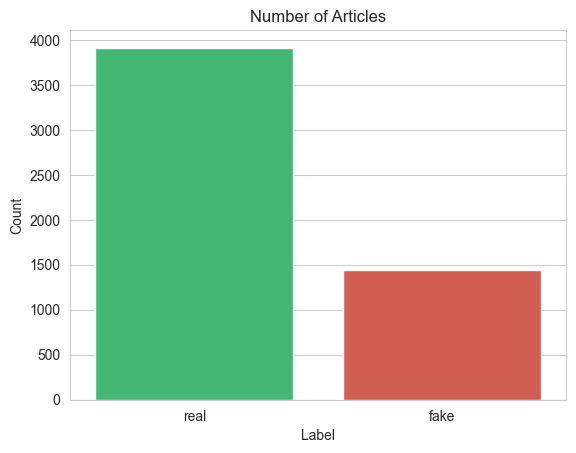

In [14]:
sns.countplot(
    data=df,
    x='Label',
    hue='Label',
    palette=['#2ecc71', '#e74c3c'],
    legend=False,
    order=['real', 'fake']
)

plt.title('Number of Articles')
plt.xlabel('Label')
plt.ylabel('Count')
plt.show()

### 3.4 Percentage of Articles by Label
Visualize the percentage distribution of real and fake news articles using a pie chart.

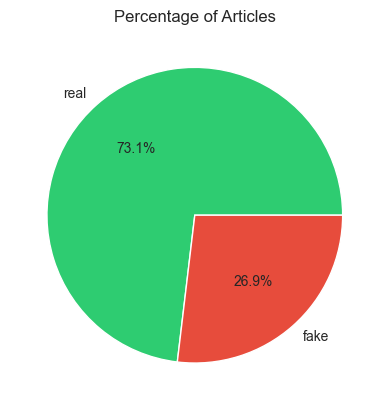

In [15]:
plt.pie(
    label_counts,
    labels=label_counts.index,
    autopct='%1.1f%%',
    colors=['#2ecc71', '#e74c3c']
)

plt.title('Percentage of Articles')
plt.show()

> **Observation:** The data is **imbalanced**: there are far more real articles than fake ones.
> So accuracy alone is not enough, and we will also look at precision, recall and F1-score for each class.

### 3.5 Article length
Do fake and real articles have different lengths? We count the number of words in each article.

### 3.5 Article Word Count
Calculate the number of words in each news article.

In [17]:
df['word_count'] = df['News content'].str.split().str.len()

### 3.6 Word Count Statistics by Label
Display descriptive statistics of article lengths for real and fake news articles, including the mean, standard deviation, minimum, maximum, and quartiles.

In [18]:
print(df.groupby('Label')['word_count'].describe().round(1))

        count   mean    std  min   25%    50%    75%      max
Label                                                        
fake   1439.0   88.5  242.9  1.0  23.0   34.0   49.5   2598.0
real   3913.0  272.6  451.3  2.0  20.0  140.0  375.0  10717.0


### 3.7 Article Length Distribution
Visualize the distribution of article lengths for real and fake news articles using a histogram.

Articles containing 1000 words or more are excluded to improve visualization clarity.

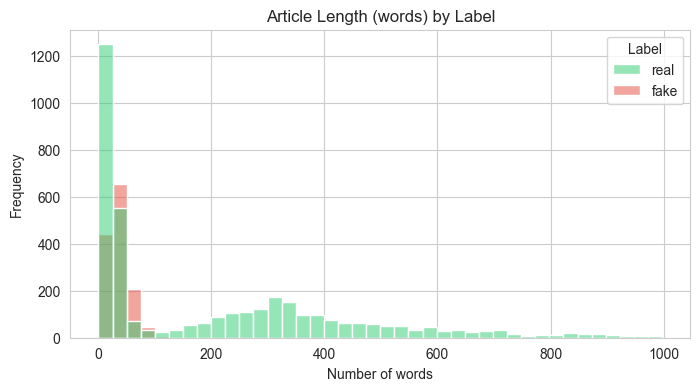

In [19]:
short_articles = df[df['word_count'] < 1000]

plt.figure(figsize=(8, 4))

sns.histplot(
    data=short_articles,
    x='word_count',
    hue='Label',
    bins=40,
    palette={'real': '#2ecc71', 'fake': '#e74c3c'}
)

plt.title('Article Length (words) by Label')
plt.xlabel('Number of words')
plt.ylabel('Frequency')
plt.show()

### Sources (platforms)
Where do the articles come from?

### 3.8 Top 5 Platforms
Identify and visualize the five platforms with the highest number of news articles.

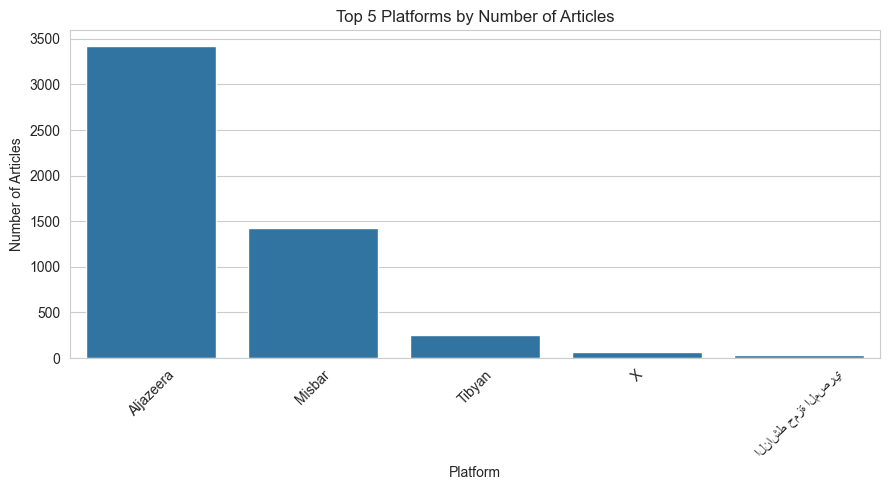

In [21]:
top_platforms = df['platform'].value_counts().head(5)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=top_platforms.index,
    y=top_platforms.values
)

plt.title('Top 5 Platforms by Number of Articles')
plt.xlabel('Platform')
plt.ylabel('Number of Articles')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 3.9 Real vs Fake News Across Top 5 Platforms
Compare the distribution of real and fake news articles across the five most frequent platforms using a grouped bar chart.

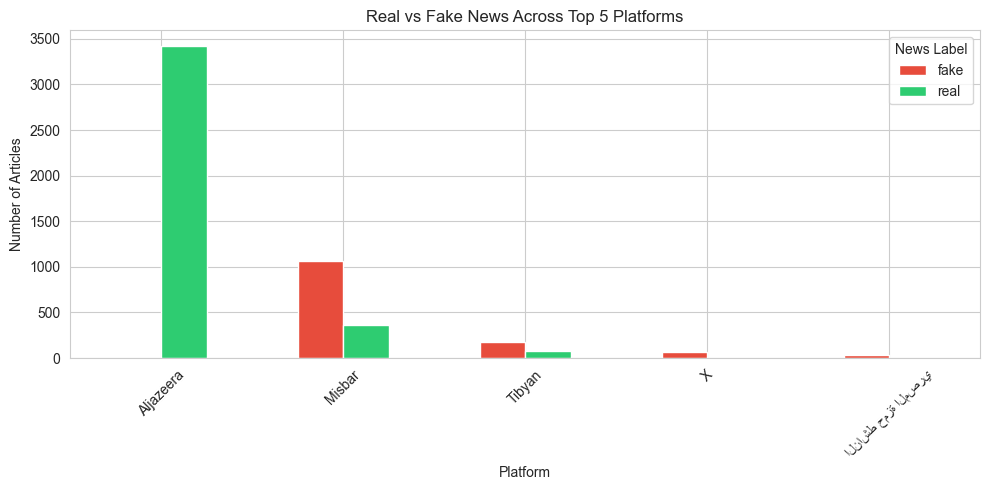

In [22]:
top_df = df[df['platform'].isin(top_platforms.index)]

platform_labels = pd.crosstab(
    top_df['platform'],
    top_df['Label']
)

platform_labels.plot(
    kind='bar',
    figsize=(10, 5),
    color=['#e74c3c', '#2ecc71']
)

plt.title('Real vs Fake News Across Top 5 Platforms')
plt.xlabel('Platform')
plt.ylabel('Number of Articles')
plt.xticks(rotation=45)
plt.legend(title='News Label')
plt.tight_layout()
plt.show()

In [20]:
top_platforms = df['platform'].value_counts().head(5)
print(top_platforms)

# Real vs fake for the top 5 platforms
top_df = df[df['platform'].isin(top_platforms.index)]
pd.crosstab(top_df['platform'], top_df['Label'])

platform
Aljazeera             3422
Misbar                1426
Tibyan                 247
X                       64
الناشط حمزة المصري      37
Name: count, dtype: int64


Label,fake,real
platform,,
Aljazeera,0,3422
Misbar,1061,365
Tibyan,174,73
X,63,1
الناشط حمزة المصري,37,0


> **Note:** Some platforms contain only one label (for example, one source is almost 100% real).
> Our models use **only the news text** (not the platform), so there is no leakage from this column,
> but it is useful to know that the source and the label are related.

## 4. Text Preprocessing

Arabic text needs special cleaning. We do the following:

| Step | What it does | Example |
|------|--------------|---------|
| Remove diacritics | Removes tashkeel | `مُحَمَّد` → `محمد` |
| Normalize letters | `أ إ آ` → `ا` ، `ة` → `ه` ، `ى` → `ي` | `مدرسة` → `مدرسه` |
| Remove punctuation and numbers | Keeps only words | `الخبر، 2023!` → `الخبر` |
| Remove stop-words | Removes common words like `في` and `من` | |
| Stemming | Reduces each word to its root | `يكتبون` → `كتب` |

In [23]:
def clean_arabic_text(text):
    # 1. Remove diacritics (tashkeel)
    text = re.sub(r'[\u064B-\u065F]', '', text)
    # 2. Normalize letters
    text = text.replace('أ', 'ا').replace('إ', 'ا').replace('آ', 'ا')
    text = text.replace('ة', 'ه')
    text = text.replace('ى', 'ي')
    # 3. Remove punctuation and numbers
    text = re.sub(r'[^\w\s]', ' ', text)
    text = re.sub(r'\d+', ' ', text)
    # 4. Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()
    return text

In [24]:
# Clean the stop-words with the same function so they match the cleaned text
stop_words = set(clean_arabic_text(word) for word in stopwords.words('arabic'))
stemmer = ISRIStemmer()

def preprocess_text(text):
    text = clean_arabic_text(text)
    words = text.split()
    words = [stemmer.stem(word) for word in words if word not in stop_words]
    return ' '.join(words)

In [25]:
# Apply the preprocessing to all articles (may take a minute)
df['processed_text'] = df['News content'].apply(preprocess_text)

In [26]:
# Before vs after for one article
sample = df['News content'].iloc[0]
print("Before:", sample[:200])
print()
print("After: ", preprocess_text(sample)[:200])

Before: هدمت قوات الاحتلال الإسرائيلي -اليوم الأربعاء- 17 منزلا تاريخيا قرب بيت لحم، بينما انطلقت مسيرات حاشدة للتنديد بالعدوان الإسرائيلي على قطاعغزةفي مناطق متفرقة منالضفة الغربية، ومن جانبها حذرت واشنطن وا

After:  هدم قوت حلل اسرائيلي اليوم ربعاء زلا ارخ قرب بيت لحم بين طلق سير حشد ندد عدو اسرائيلي قطاعغزهفي نطق تفرق منالضف غرب جنب حذر شنط امم تحد عدء وطن مره لسط وقل حسن برج دير كتب هيئ قام جدر سيط بمد بيت لحم 


### Most common words
After preprocessing, which words appear most in real and fake news?

In [27]:
def top_words(label, n=10):
    all_text = ' '.join(df[df['Label'] == label]['processed_text'])
    return Counter(all_text.split()).most_common(n)

pd.DataFrame({
    'Real news': top_words('real'),
    'Fake news': top_words('fake')
})

,Real news,Fake news
0,"(غزه, 10227)","(غزه, 1663)"
1,"(اسرائيلي, 8870)","(قطع, 1624)"
2,"(قطع, 7649)","(جمع, 1053)"
3,"(حلل, 7044)","(حسب, 989)"
4,"(لسط, 6143)","(وقع, 983)"
5,"(عمل, 5749)","(اسرائيلي, 961)"
6,"(اسرائيليه, 5323)","(يدو, 951)"
7,"(جمع, 5153)","(نشر, 932)"
8,"(رائيل, 5000)","(حدث, 870)"
9,"(حرب, 4519)","(دول, 868)"


## 5. Prepare the Data for the Models

### 5.1 Train / Test split
- 80% of the data for training, 20% for testing.
- `stratify=y` keeps the same real/fake ratio in both parts (important because the data is imbalanced).
- Labels become numbers: **real = 1**, **fake = 0**.

In [28]:
X = df['processed_text']
y = df['Label'].map({'real': 1, 'fake': 0})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training size:", len(X_train))
print("Testing size: ", len(X_test))

Training size: 4281
Testing size:  1071


### 5.2 TF-IDF
Models can't read text, so we convert each article to numbers.
**TF-IDF** gives a higher score to words that are important in an article but not common everywhere.
We keep the 5000 most useful words.

In [29]:
tfidf = TfidfVectorizer(max_features=5000)

X_train_tfidf = tfidf.fit_transform(X_train)   # learn the words from training data only
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF shape (articles, words):", X_train_tfidf.shape)

TF-IDF shape (articles, words): (4281, 5000)


## 6. Train the Models

We train three different models on the same data:

| Model | Idea |
|-------|------|
| **Logistic Regression** | Simple model that draws a line between the two classes |
| **Random Forest** | Many decision trees vote together |
| **SVM (linear)** | Finds the best separating line with the widest margin |

In [30]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'SVM': SVC(kernel='linear', C=1.0, random_state=42),
}

predictions = {}   # we save each model's predictions here

for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    predictions[name] = model.predict(X_test_tfidf)
    print(f"{name} trained ✔")

Logistic Regression trained ✔
Random Forest trained ✔
SVM trained ✔


## 7. Evaluation

### 7.1 Detailed report for each model
**How to read it:**
- **Precision:** of all articles predicted as a class, how many were correct?
- **Recall:** of all real articles of a class, how many did we find?
- **F1-score:** a balance between precision and recall.

(Class `0` = fake, class `1` = real)

In [31]:
for name, y_pred in predictions.items():
    print(f"===== {name} =====")
    print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
    print(classification_report(y_test, y_pred, target_names=['Fake', 'Real']))

===== Logistic Regression =====
Accuracy: 0.8805
              precision    recall  f1-score   support

        Fake       0.81      0.72      0.76       288
        Real       0.90      0.94      0.92       783

    accuracy                           0.88      1071
   macro avg       0.86      0.83      0.84      1071
weighted avg       0.88      0.88      0.88      1071

===== Random Forest =====
Accuracy: 0.8936
              precision    recall  f1-score   support

        Fake       0.83      0.76      0.79       288
        Real       0.91      0.94      0.93       783

    accuracy                           0.89      1071
   macro avg       0.87      0.85      0.86      1071
weighted avg       0.89      0.89      0.89      1071

===== SVM =====
Accuracy: 0.8842
              precision    recall  f1-score   support

        Fake       0.78      0.79      0.79       288
        Real       0.92      0.92      0.92       783

    accuracy                           0.88      1071
   

### 7.2 Confusion matrices
Each square shows how many articles were predicted correctly (diagonal) and wrongly (outside the diagonal).

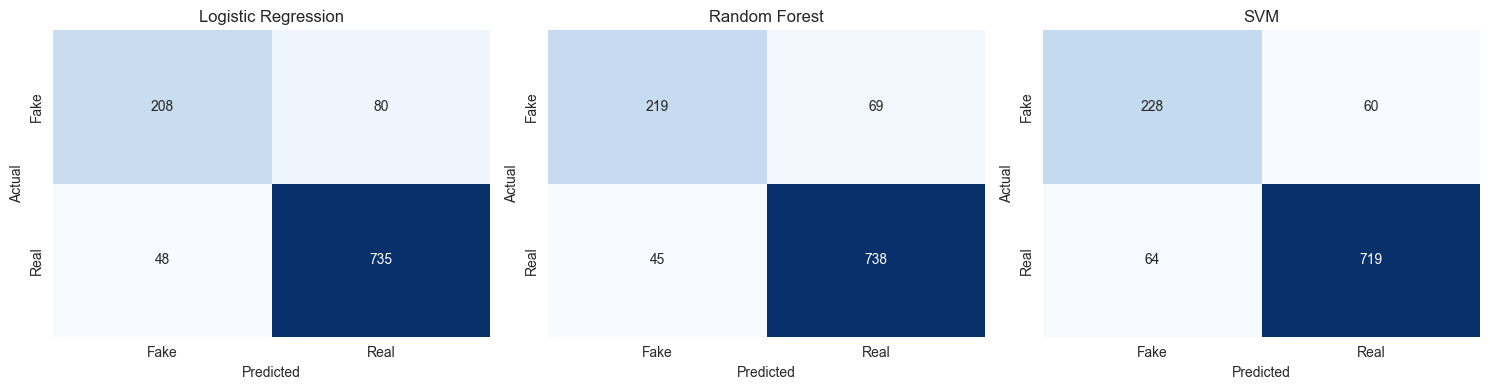

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Fake', 'Real'], yticklabels=['Fake', 'Real'], ax=ax)
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

### 7.3 Model comparison
We put the main scores of all models in one table and one chart.
We use **macro F1** because it treats fake and real classes equally, which is important with imbalanced data.

In [33]:
results = pd.DataFrame({
    'Accuracy': {name: accuracy_score(y_test, p) for name, p in predictions.items()},
    'Macro F1': {name: f1_score(y_test, p, average='macro') for name, p in predictions.items()},
}).round(4)

results

,Accuracy,Macro F1
Logistic Regression,0.8805,0.8423
Random Forest,0.8936,0.8609
SVM,0.8842,0.8534


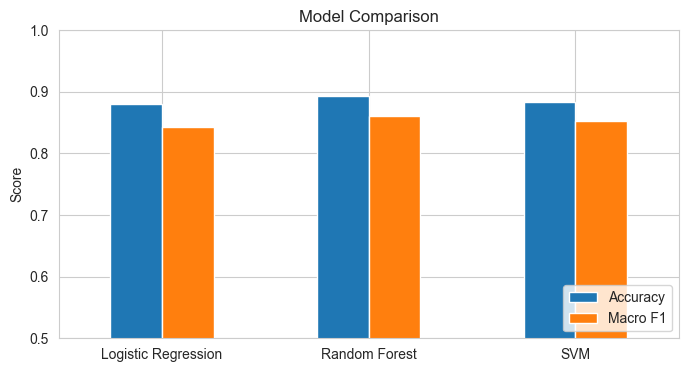

In [34]:
results.plot(kind='bar', figsize=(8, 4), rot=0, ylim=(0.5, 1))
plt.title('Model Comparison')
plt.ylabel('Score')
plt.legend(loc='lower right')
plt.show()

## 8. Try the Model on New Text

A small function that takes any Arabic news text and tells us if it looks real or fake.

In [35]:
best_model_name = results['Macro F1'].idxmax()
best_model = models[best_model_name]
print("Best model:", best_model_name)

def predict_news(text):
    processed = preprocess_text(text)
    features = tfidf.transform([processed])
    result = best_model.predict(features)[0]
    return 'Real' if result == 1 else 'Fake'

Best model: Random Forest


In [36]:
# Test on 5 random articles from the test set
test_samples = df.loc[X_test.sample(5, random_state=1).index]

for _, row in test_samples.iterrows():
    print("Text:     ", row['News content'][:100], "...")
    print("Actual:   ", row['Label'].capitalize())
    print("Predicted:", predict_news(row['News content']))
    print('-' * 40)

Text:      اعتبرت حركة المقاومة الإسلامية (حماس) أن قصف قوات الاحتلال الإسرائيلي مركز توزيع مساعدات في جباليا ش ...
Actual:    Real
Predicted: Real
----------------------------------------
Text:      هل توقفت فعاليات الشباب الثائر شرق غزة؟؟ ...
Actual:    Real
Predicted: Real
----------------------------------------
Text:      شدد عدد من قادة دول العالم في كلماتهم أمام الجمعية العامة للأمم المتحدة، الثلاثاء، على ضرورة وقف الح ...
Actual:    Real
Predicted: Real
----------------------------------------
Text:      تعود الصورتان إلى مظاهرات خرجت في #الجزائر في السادس من إبريل عام 2019، لمُطالبة الإمارات بعدم التدخ ...
Actual:    Fake
Predicted: Fake
----------------------------------------
Text:      الفيديو يضم في بدايته ونهايته مشاهد بثتها كتائب القسام الذراع العسكري لحركة حماس، في السابع من أكتوب ...
Actual:    Fake
Predicted: Fake
----------------------------------------


## 9. Conclusion

In [37]:
best_accuracy = results.loc[best_model_name, 'Accuracy']
best_f1 = results.loc[best_model_name, 'Macro F1']

print(f"Best model: {best_model_name}")
print(f"Accuracy:   {best_accuracy:.2%}")
print(f"Macro F1:   {best_f1:.2%}")

Best model: Random Forest
Accuracy:   89.36%
Macro F1:   86.09%


### Created by : Mohamed Ayman 🫶